# Student Details
## Name: Neeraj R Rugi
## SRN: PES2UG24CS311

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Practical Notebook: Investigating Payment-Fraud Patterns

### Background

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Execute this supplied cell without changes. It imports `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Start with a Month-Level Overview (Request #1)

**Practical context:** Fraud analysis should begin with a summary of the full observation period rather than an isolated queue of alerts.

**Concept being applied:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**Tasks to complete:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Create a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

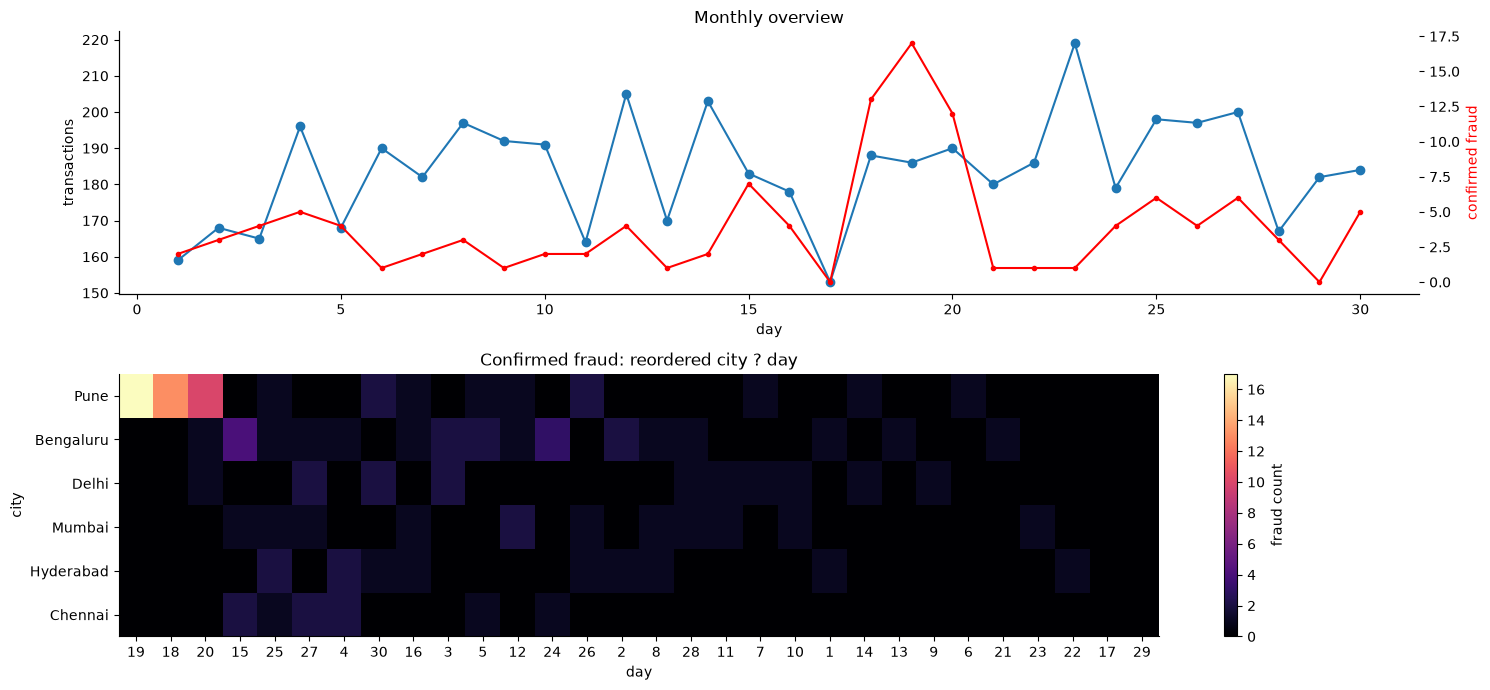

Most-fraud city/day cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
daily = tx.groupby("day").agg(transactions=("txn_id", "size"), fraud=("is_fraud", "sum"))
ax2 = axes[0].twinx(); axes[0].plot(daily.index, daily.transactions, "o-", label="transactions"); ax2.plot(daily.index, daily.fraud, "r.-", label="confirmed fraud")
axes[0].set(xlabel="day", ylabel="transactions"); ax2.set_ylabel("confirmed fraud", color="red"); axes[0].set_title("Monthly overview")
city_day = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
city_day = city_day.loc[city_day.sum(axis=1).sort_values(ascending=False).index, city_day.sum(axis=0).sort_values(ascending=False).index]
heat = city_day
im = axes[1].imshow(heat, aspect="auto", cmap="magma"); axes[1].set(yticks=np.arange(len(heat.index)), yticklabels=heat.index, xticks=np.arange(len(heat.columns)), xticklabels=heat.columns, xlabel="day", ylabel="city", title="Confirmed fraud: reordered city ? day")
plt.colorbar(im, ax=axes[1], label="fraud count")
plt.tight_layout(); plt.show()
print("Most-fraud city/day cells:")
print(city_day.stack().sort_values(ascending=False).head(10))


**Think about and explain:** The summary displayed daily concentrations by city, highlighting recurring clusters that an alert list, organized by detector score, would distribute throughout the page. Rearranging the matrix revealed those patterns through the **reordered matrix/overview-first** concept discussed in the lecture.


## Task 2 — Coordinated Views of Night-Time, Distant Transactions (Request #2)

**Practical context:** Analysts can test a proposed risk pattern by selecting matching records and observing how that selection appears in several linked charts.

**Concept being applied:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**Tasks to complete:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

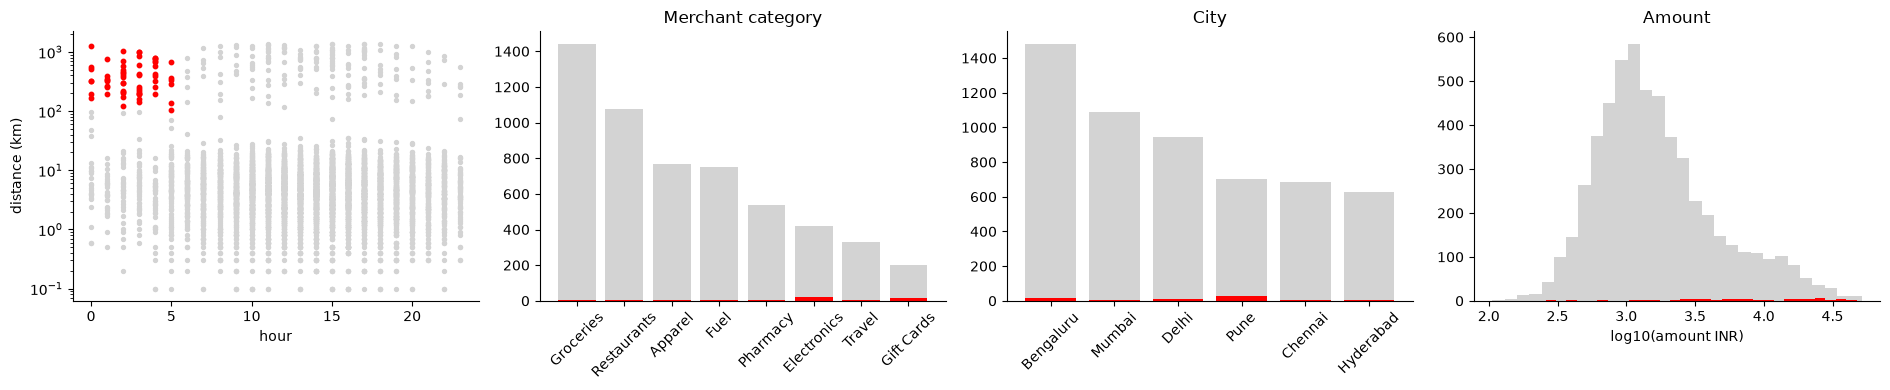

Brushed: 61 | fraud rate in brush: 0.869 | overall: 0.022 | share of all fraud: 0.442


In [3]:
brush = (tx.night & (tx.distance_from_home_km > 100))
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].scatter(tx.hour, tx.distance_from_home_km, c="lightgrey", s=8); axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], c="red", s=10); axes[0].set(yscale="log", xlabel="hour", ylabel="distance (km)")
for col, title, ax in [("merchant_category", "Merchant category", axes[1]), ("city", "City", axes[2])]:
    all_counts = tx[col].value_counts(); selected_counts = tx.loc[brush, col].value_counts().reindex(all_counts.index, fill_value=0)
    x = np.arange(len(all_counts)); ax.bar(x, all_counts.values, color="lightgrey"); ax.bar(x, selected_counts.values, color="red"); ax.set(xticks=x, xticklabels=all_counts.index, title=title); ax.tick_params(axis="x", rotation=45)
axes[3].hist(np.log10(tx.amount_inr), bins=30, color="lightgrey"); axes[3].hist(np.log10(tx.loc[brush, "amount_inr"]), bins=30, color="red"); axes[3].set(xlabel="log10(amount INR)", title="Amount")
plt.tight_layout(); plt.show()
print(f"Brushed: {brush.sum()} | fraud rate in brush: {tx.loc[brush, 'is_fraud'].mean():.3f} | overall: {tx.is_fraud.mean():.3f} | share of all fraud: {tx.loc[brush, 'is_fraud'].sum() / tx.is_fraud.sum():.3f}")


**Think about and explain:** The brush exhibits a significant fraud rate; however, it only detects a portion of all fraudulent activities. Therefore, relying solely on night-time distance would result in false negatives. Insights from city or merchant-linked views uncover fraudulent activities beyond the brush, indicating areas where investigators should search for additional patterns.


## Task 3 — Testing Interactive Filter Performance (Request #3)

**Practical context:** The expected response time should be measured before committing to an interactive design.

**Concept being applied:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**Tasks to complete:**
1. Create a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Calculate the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

mask = (big.detector_score >= 0.6) & (big.amount_inr > 3000)
times = []
for _ in range(5):
    start = time.perf_counter(); _ = big.loc[mask]; times.append(time.perf_counter() - start)
best_s = min(times)
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 4.0 ms -> 0.0040 us/row -> max 25,020,977 rows in 0.1 s
50M rows -> 0.20 s; must skip 50.0% of rows to stay under 0.1 s


**Think about and explain:** Pre-aggregation would ensure that the slider operates instantly by querying summary bins instead of examining each transaction. However, the analyst would forfeit precise transaction-level details within each bin and would require a drill-down to retrieve individual cases.


## Task 4 — Selecting a Threshold Within Review Capacity (Request #4)

**Practical context:** A useful alert cutoff must reflect the team's review capacity as well as model-performance metrics.

**Concept being applied:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**Tasks to complete:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Determine the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Create a plot of the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Output a brief recommendation based on your results.

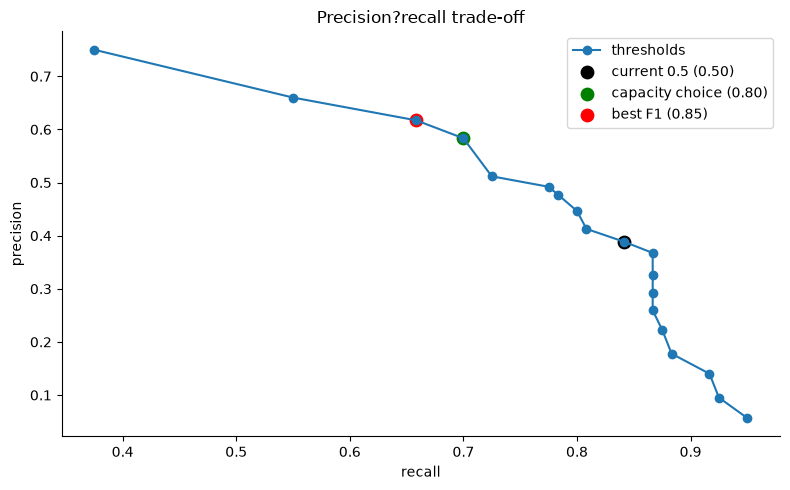

Recommendation: use threshold 0.80 (144.0 alerts, recall 0.700); best F1 is 0.85.


In [5]:
rows = []
for threshold in np.arange(0.05, 1.0, 0.05):
    flagged = tx.detector_score >= threshold
    tp = int((flagged & (tx.is_fraud == 1)).sum()); fp = int((flagged & (tx.is_fraud == 0)).sum()); fn = int((~flagged & (tx.is_fraud == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0; recall = tp / (tp + fn) if tp + fn else 0; f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    rows.append({"threshold": round(threshold, 2), "alerts": int(flagged.sum()), "tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1})
pr = pd.DataFrame(rows)
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "o-", label="thresholds")
for row, label, color in [(pr.iloc[(pr.threshold - 0.5).abs().argmin()], "current 0.5", "black"), (capacity_choice, "capacity choice", "green"), (best_f1, "best F1", "red")]: ax.scatter(row.recall, row.precision, s=80, color=color, label=f"{label} ({row.threshold:.2f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision?recall trade-off"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Recommendation: use threshold {capacity_choice.threshold:.2f} ({capacity_choice.alerts} alerts, recall {capacity_choice.recall:.3f}); best F1 is {best_f1.threshold:.2f}.")


**Think about and explain:** The Head of Fraud Operations ought to make the decision based on the model as evidence, since factors such as capacity, investigation costs, and the risk of missed fraud are operational choices rather than solely statistical goals. Visual analytics ensures that a human remains involved, allowing the individual responsible for the outcomes to evaluate trade-offs, modify the threshold, and integrate context that the labels fail to capture.



## Task 5 — Creating an Interactive Case-Review Tool (Request #5)

**Practical context:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Concept being applied:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**Tasks to complete:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
flagged = tx[tx.detector_score >= 0.3].copy()
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                 hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
                 title="Flagged transactions: details on demand")
fig.update_layout(dragmode="select"); fig.show()
summary = tx.groupby(["city", "merchant_category"], as_index=False).agg(transactions=("txn_id", "size"), fraud_rate=("is_fraud", "mean"))
fig_sun = px.sunburst(summary, path=["city", "merchant_category"], values="transactions", color="fraud_rate", color_continuous_scale="Reds", title="Drill-down: city ? merchant category")
fig_sun.show()


**Think about and explain:** Tooltips compel investigators to examine cases individually, preventing them from swiftly comparing the distribution of 400 flagged cases or identifying clusters. The associated overview/heatmap and coordinated views address this issue by initially displaying aggregate patterns while still allowing for detailed views of selected cases.

## Task 6 — Evaluate the Possible City-Based Fraud Cluster (Request #6)

**Practical context:** Before treating the pattern as evidence of coordinated criminal activity, compare it with plausible alternative explanations.

**Concept being applied:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**Tasks to complete:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Calculate the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Test alternative explanations by calculating: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Check the result visually by creating: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Display your conclusion.

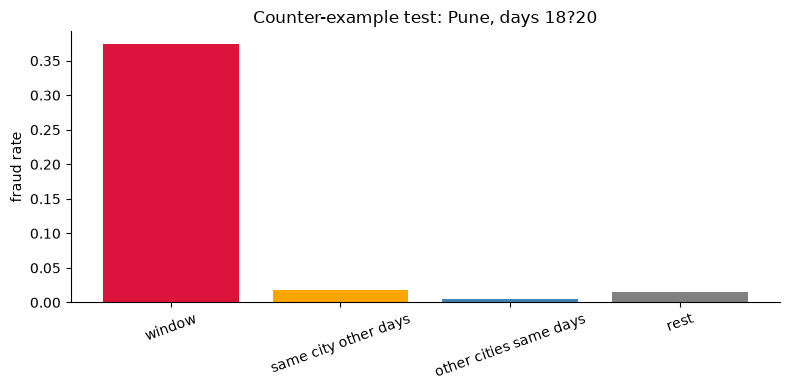

Hypothesis: fraud was concentrated in Pune during days 18?20.
Rates: {'window': np.float64(0.37383177570093457), 'same city other days': np.float64(0.01854974704890388), 'other cities same days': np.float64(0.00437636761487965), 'rest': np.float64(0.015356406142562456)} | chi-square p-value: 1.065e-136
Verdict: supported


In [7]:
from scipy.stats import chi2_contingency

top_city, top_day = tx.groupby(["city", "day"]).is_fraud.sum().idxmax()
in_window = (tx.city == top_city) & tx.day.between(top_day - 1, top_day + 1)
contingency = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, _, _ = chi2_contingency(contingency)

same_city_other_days = (tx.city == top_city) & ~in_window
other_cities_same_days = (tx.city != top_city) & tx.day.between(top_day - 1, top_day + 1)
rest = ~(in_window | same_city_other_days | other_cities_same_days)
groups = {"window": in_window, "same city other days": same_city_other_days, "other cities same days": other_cities_same_days, "rest": rest}
rates = {name: tx.loc[mask, "is_fraud"].mean() for name, mask in groups.items()}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(rates), list(rates.values()), color=["crimson", "orange", "steelblue", "grey"]); ax.set_ylabel("fraud rate"); ax.set_title(f"Counter-example test: {top_city}, days {top_day-1}?{top_day+1}"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(f"Hypothesis: fraud was concentrated in {top_city} during days {top_day-1}?{top_day+1}.")
print(f"Rates: {rates} | chi-square p-value: {p_value:.4g}")
print("Verdict: supported" if rates["window"] > rates["same city other days"] and rates["window"] > rates["other cities same days"] and p_value < 0.05 else "Verdict: not supported")


**Think about and explain:** If the comparison of the same city on different days reveals a similarly high fraud rate, it would invalidate the hypothesis, as this would indicate a consistent city-specific mix of customers or merchants rather than a temporary fraud ring. Conversely, a high fraud rate in other cities on the same days would suggest the presence of a wider time-based campaign or an issue related to detector/data quality.


**Your concluding recommendation:** The month recorded a total of 5,520 transactions alongside 120 confirmed cases of fraud, with the highest concentration observed in the Pune window on specific city-days. I suggest implementing the capacity-constrained threshold derived from the precision/recall table, as it adheres to the monthly limit of 150 alerts while clearly delineating the recall trade-off; this proposal should be sanctioned by the Head of Fraud Operations, who serves as the human decision-maker. Initially, develop the linked overview and brushing tool, prioritizing an overview-first approach that integrates linked highlighting and details-on-demand, rather than solely depending on tooltips. Evaluating the dynamic query will determine if pre-aggregation is necessary to comply with the 0.1-second response time requirement. Furthermore, establish a feedback loop to capture investigator decisions and newly confirmed labels, which should be reviewed for false positives and negatives, and utilized to retrain and recalibrate the detection system.
